# 👥 Dipendenti che lasciano l'azienda – Analisi

**Progetto di Francesco Autorino – Data Analyst**

🏢 1.470 dipendenti, il 16% ha lasciato l'azienda.

❓ **Le 6 domande**
1. Quanti dipendenti escono, e da quali reparti e ruoli?
2. Straordinari e trasferte spingono ad andare via?
3. Stipendio e carriera contano?
4. Quanto pesano soddisfazione ed equilibrio vita-lavoro?
5. Qual è il profilo di chi esce?
6. Si può prevedere chi uscirà? (modello di regressione logistica)

⚠️ Dataset **fittizio** creato da IBM per esercitarsi: i risultati mostrano un metodo, non un'azienda reale.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

PULITI = Path("../02Dati/2Puliti"); GRAFICI = Path("Grafici"); GRAFICI.mkdir(exist_ok=True)
d = pd.read_csv(PULITI / "dipendenti.csv"); fat = pd.read_csv(PULITI / "fattori.csv")
MEDIA = d.uscito_num.mean()
ESCE, RESTA, BLU, GRIGIO = "#eb6834", "#1f4e9c", "#1f4e9c", "#9a9890"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0", "axes.axisbelow": True,
                     "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left"})
def salva(n):
    plt.tight_layout(); plt.savefig(GRAFICI / f"{n}.png", bbox_inches="tight", facecolor="white"); plt.show()

def barre_tasso(ax, fattore, titolo, ordina=False):
    t = fat[fat.fattore == fattore].sort_values("tasso_uscita_pct" if ordina else "ordine")
    colori = [ESCE if v > MEDIA * 100 else RESTA for v in t.tasso_uscita_pct]
    ax.bar(t.valore, t.tasso_uscita_pct, color=colori, width=0.65)
    ax.axhline(MEDIA * 100, color=GRIGIO, ls="--", lw=1)
    for x, (v, n) in enumerate(zip(t.tasso_uscita_pct, t.dipendenti)):
        ax.text(x, v + 0.8, f"{v:.0f}%", ha="center", fontsize=9, color="#52514e")
    ax.set_title(titolo); ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.grid(axis="x", visible=False)

def chi2(col):
    t = pd.crosstab(d[col], d.uscito); c, p, _, _ = stats.chi2_contingency(t)
    v = np.sqrt(c / (len(d) * (min(t.shape) - 1)))
    return f"chi-quadro p = {p:.1e} · V di Cramér = {v:.2f}"
print(f"Dipendenti: {len(d):,} · Usciti: {d.uscito_num.sum()} · Tasso medio: {MEDIA:.1%}")

Dipendenti: 1,470 · Usciti: 237 · Tasso medio: 16.1%


## 🏢 1. Quanti escono, e da dove?

La linea tratteggiata è la media aziendale (16%). In **arancione** i gruppi sopra la media.

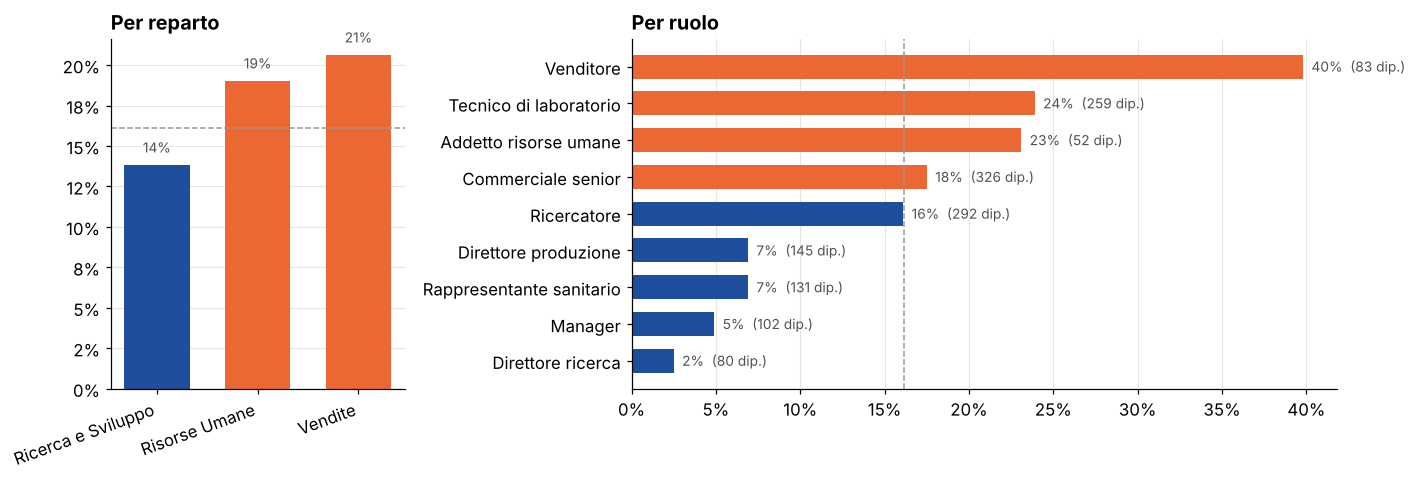

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 2.4]})
barre_tasso(ax[0], "Reparto", "Per reparto")
r = fat[fat.fattore == "Ruolo"].sort_values("tasso_uscita_pct")
ax[1].barh(r.valore, r.tasso_uscita_pct, color=[ESCE if v > MEDIA*100 else RESTA for v in r.tasso_uscita_pct], height=0.65)
ax[1].axvline(MEDIA * 100, color=GRIGIO, ls="--", lw=1)
for y, (v, n) in enumerate(zip(r.tasso_uscita_pct, r.dipendenti)):
    ax[1].text(v + 0.5, y, f"{v:.0f}%  ({n} dip.)", va="center", fontsize=9, color="#52514e")
ax[1].set_title("Per ruolo"); ax[1].xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax[1].grid(axis="y", visible=False)
plt.setp(ax[0].get_xticklabels(), rotation=20, ha="right")
salva("01_reparti_ruoli")

📝 Il reparto **Vendite** perde il 21% delle persone, **Ricerca e Sviluppo** il 14%.

📝 Il ruolo più a rischio è il **Venditore**: esce **4 su 10**. Seguono tecnici di laboratorio e addetti alle risorse umane.

📝 Manager e direttori quasi non escono (2-7%).

## ⏰ 2. Straordinari e trasferte

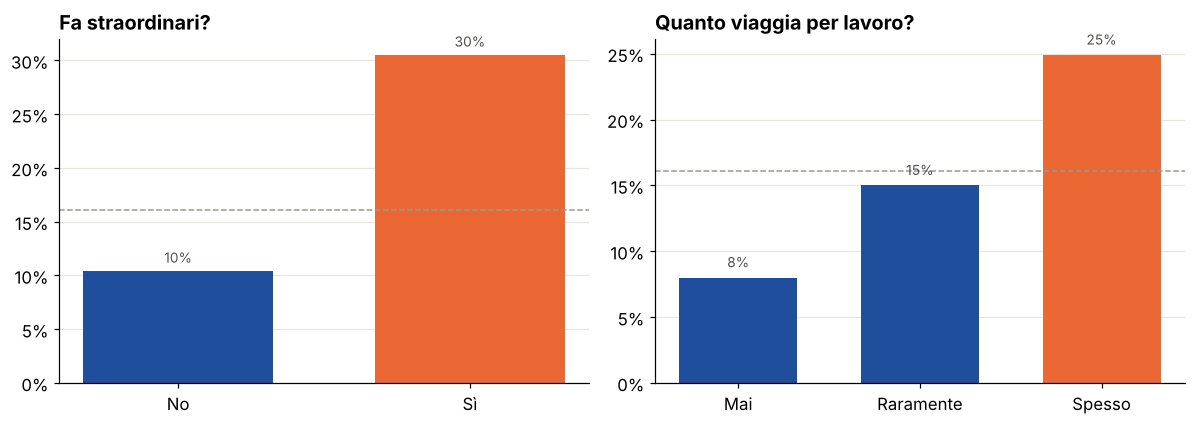

Straordinari → chi-quadro p = 8.2e-21 · V di Cramér = 0.24
Trasferte    → chi-quadro p = 5.6e-06 · V di Cramér = 0.13


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
barre_tasso(ax[0], "Straordinari", "Fa straordinari?")
barre_tasso(ax[1], "Trasferte", "Quanto viaggia per lavoro?")
salva("02_straordinari_trasferte")
print("Straordinari →", chi2("straordinari")); print("Trasferte    →", chi2("trasferte"))

📝 Chi fa **straordinari** esce 3 volte di più: **31%** contro 10%. È il fattore più forte di tutti.

📝 Chi viaggia **spesso** esce il 25% delle volte, chi non viaggia mai solo l'8%.

📝 Il test chi-quadro conferma: le differenze non sono dovute al caso.

## 💰 3. Stipendio e carriera

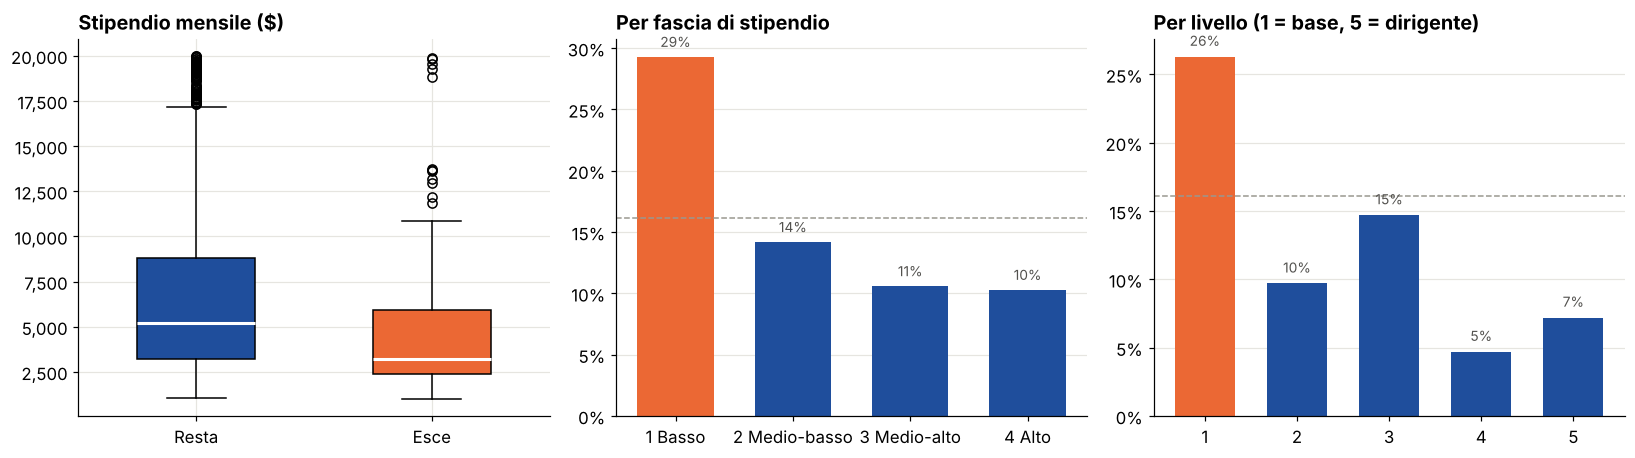

Stipendio mediano: chi resta 5,204 $ · chi esce 3,202 $ (Mann-Whitney p = 3.0e-14)


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
dati = [d[d.uscito == "No"].stipendio_mensile, d[d.uscito == "Sì"].stipendio_mensile]
b = ax[0].boxplot(dati, tick_labels=["Resta", "Esce"], patch_artist=True, widths=0.5, medianprops=dict(color="white", lw=2))
for p, c in zip(b["boxes"], [RESTA, ESCE]): p.set_facecolor(c)
ax[0].set_title("Stipendio mensile ($)"); ax[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
barre_tasso(ax[1], "Fascia di stipendio", "Per fascia di stipendio")
barre_tasso(ax[2], "Livello", "Per livello (1 = base, 5 = dirigente)")
salva("03_stipendio_livello")
u, p = stats.mannwhitneyu(*dati)
print(f"Stipendio mediano: chi resta {dati[0].median():,.0f} $ · chi esce {dati[1].median():,.0f} $ (Mann-Whitney p = {p:.1e})")

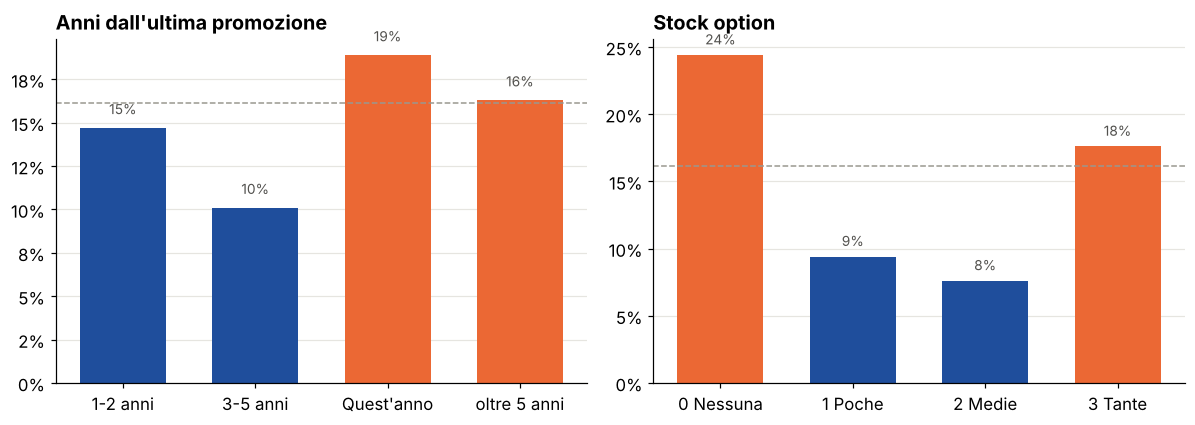

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
barre_tasso(ax[0], "Ultima promozione", "Anni dall'ultima promozione")
barre_tasso(ax[1], "Stock option", "Stock option")
salva("04_promozione_stock")

📝 Chi esce guadagna molto meno: stipendio mediano circa **3.200 $** contro 5.200 $.

📝 Nel 25% più pagato esce il 10%, nel 25% meno pagato il **29%**.

📝 Il **livello 1** (entrata) perde il 26% delle persone.

📝 Chi **non ha stock option** esce il 24% delle volte: le azioni legano le persone all'azienda.

📝 Gli anni dall'ultima promozione, da soli, sembrano contare poco. Ma nel modello (domanda 6), a parità di età e anzianità, pesano: restare fermi a lungo spinge a uscire.

## 😊 4. Soddisfazione ed equilibrio vita-lavoro

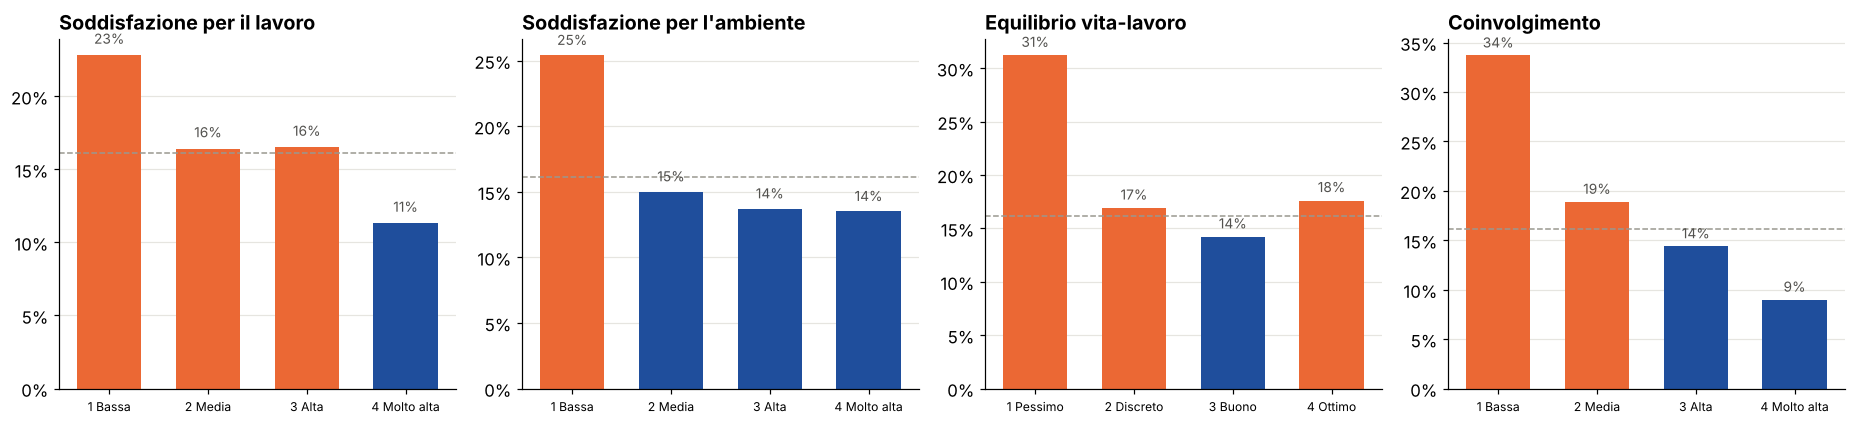

In [6]:
fig, ax = plt.subplots(1, 4, figsize=(17, 4))
for a, (f, t) in zip(ax, [("Soddisfazione lavoro", "Soddisfazione per il lavoro"), ("Soddisfazione ambiente", "Soddisfazione per l'ambiente"),
                          ("Equilibrio vita-lavoro", "Equilibrio vita-lavoro"), ("Coinvolgimento", "Coinvolgimento")]):
    barre_tasso(a, f, t); a.tick_params(axis="x", labelsize=8)
salva("05_soddisfazione")

📝 In tutti e quattro i casi il gruppo **"1 Bassa / Pessimo"** esce molto di più: dal 23% al 34%.

📝 Il **coinvolgimento basso** è il segnale più forte (34%), poi l'equilibrio vita-lavoro pessimo (31%).

💡 Un sondaggio interno ogni anno potrebbe trovare in anticipo chi rischia di andarsene.

## 🧑 5. Il profilo di chi esce

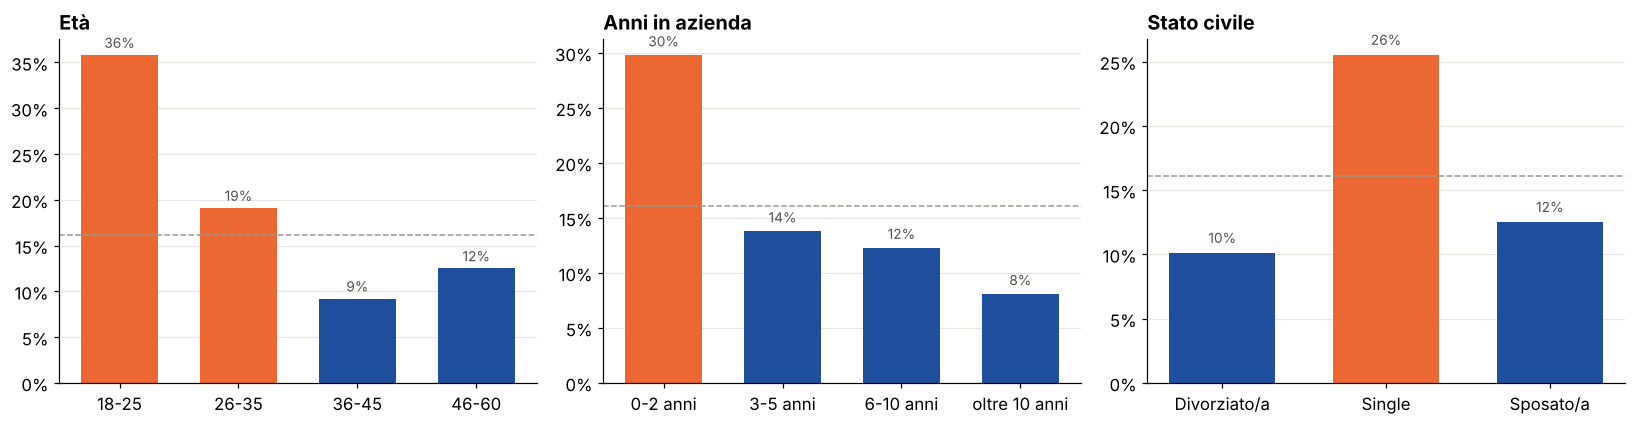

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
barre_tasso(ax[0], "Fascia di età", "Età")
barre_tasso(ax[1], "Anni in azienda", "Anni in azienda")
barre_tasso(ax[2], "Stato civile", "Stato civile")
salva("06_profilo")

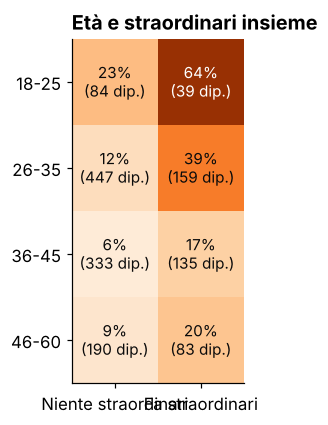

In [8]:
h = d.pivot_table(index="fascia_eta", columns="straordinari", values="uscito_num", aggfunc="mean") * 100
n = d.pivot_table(index="fascia_eta", columns="straordinari", values="uscito_num", aggfunc="size")
fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(h, cmap="Oranges", vmin=0, vmax=70)
for i in range(h.shape[0]):
    for j in range(h.shape[1]):
        ax.text(j, i, f"{h.iloc[i, j]:.0f}%\n({n.iloc[i, j]} dip.)", ha="center", va="center", fontsize=10,
                color="white" if h.iloc[i, j] > 40 else "#0b0b0b")
ax.set_xticks([0, 1], ["Niente straordinari", "Fa straordinari"]); ax.set_yticks(range(len(h)), h.index); ax.grid(False)
ax.set_title("Età e straordinari insieme")
salva("07_eta_straordinari")

📝 Escono soprattutto i **giovani** (18-25 anni: 36%), i **nuovi assunti** (0-2 anni: 30%) e i **single** (26%).

📝 Il mix più pericoloso: **giovani che fanno straordinari** → ne esce circa **2 su 3**.

## 🤖 6. Si può prevedere chi uscirà?

Uso una **regressione logistica**: un modello semplice e spiegabile. Divido i dati: 75% per allenare il modello, 25% per provarlo.

In [9]:
num = ["eta", "stipendio_mensile", "anni_in_azienda", "anni_nel_ruolo", "anni_da_promozione", "anni_con_manager",
       "anni_lavoro_totali", "aziende_precedenti", "distanza_casa_km", "formazioni_ultimo_anno", "aumento_pct", "livello"]
cat = ["straordinari", "trasferte", "reparto", "stato_civile", "stock_option", "soddisfazione_lavoro",
       "soddisfazione_ambiente", "equilibrio_vita_lavoro", "coinvolgimento", "genere", "soddisfazione_relazioni"]
X = pd.get_dummies(d[num + cat], columns=cat, drop_first=True, dtype=float)
y = d.uscito_num
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
sc = StandardScaler().fit(Xtr)
m = LogisticRegression(max_iter=2000, class_weight="balanced", C=0.5).fit(sc.transform(Xtr), ytr)
prob = m.predict_proba(sc.transform(Xte))[:, 1]; pred = (prob >= 0.5).astype(int)
cm = confusion_matrix(yte, pred)
print(f"AUC sul test: {roc_auc_score(yte, prob):.2f}  (0,5 = a caso · 1 = perfetto)")
print(f"Uscite trovate dal modello: {cm[1,1]} su {cm[1].sum()} ({cm[1,1]/cm[1].sum():.0%}) · falsi allarmi: {cm[0,1]} su {cm[0].sum()}")
print(classification_report(yte, pred, target_names=["Resta", "Esce"], digits=2))

AUC sul test: 0.82  (0,5 = a caso · 1 = perfetto)
Uscite trovate dal modello: 43 su 59 (73%) · falsi allarmi: 60 su 309
              precision    recall  f1-score   support

       Resta       0.94      0.81      0.87       309
        Esce       0.42      0.73      0.53        59

    accuracy                           0.79       368
   macro avg       0.68      0.77      0.70       368
weighted avg       0.86      0.79      0.81       368



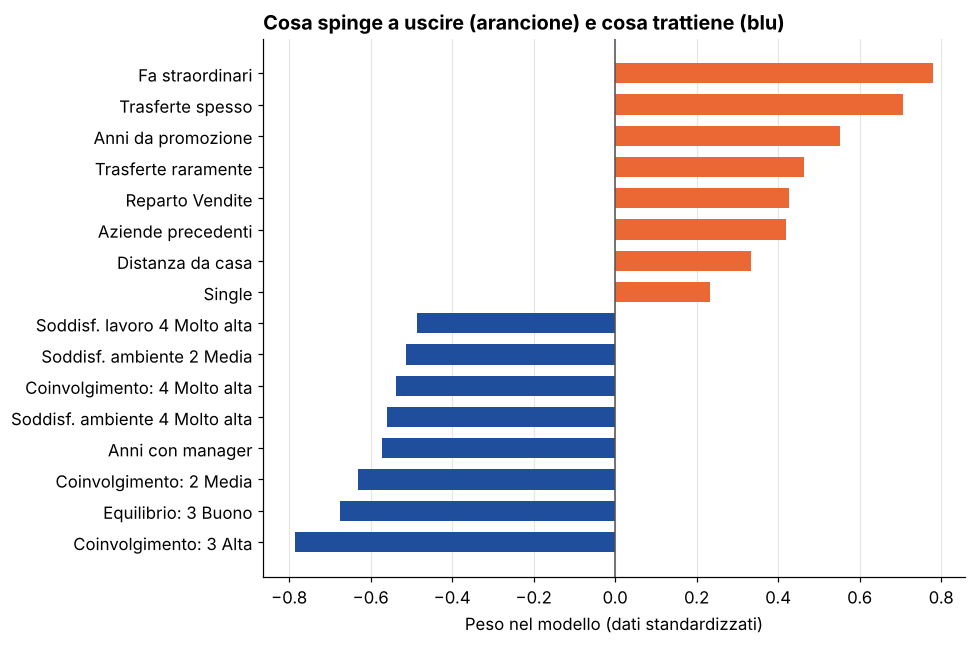

,fattore,peso,effetto
37,Fa straordinari,0.779,Spinge a uscire
36,Trasferte spesso,0.705,Spinge a uscire
35,Anni da promozione,0.553,Spinge a uscire
34,Trasferte raramente,0.464,Spinge a uscire
33,Reparto Vendite,0.427,Spinge a uscire
32,Aziende precedenti,0.419,Spinge a uscire


In [10]:
coef = pd.Series(m.coef_[0], index=X.columns).sort_values()
nomi = lambda s: (s.replace("_", " ").replace("straordinari Sì", "Fa straordinari").replace("trasferte Spesso", "Trasferte spesso")
                  .replace("stato civile Single", "Single").replace("stock option ", "Stock option: ").replace("anni ", "Anni ")
                  .replace("coinvolgimento ", "Coinvolgimento: ").replace("equilibrio vita lavoro ", "Equilibrio: ")
                  .replace("soddisfazione ", "Soddisf. ").replace("trasferte Raramente", "Trasferte raramente")
                  .replace("reparto ", "Reparto ").replace("genere Uomo", "Uomo").replace("distanza casa km", "Distanza da casa")
                  .replace("aziende precedenti", "Aziende precedenti").replace("stipendio mensile", "Stipendio"))
top = pd.concat([coef.head(8), coef.tail(8)])
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh([nomi(i) for i in top.index], top.values, color=[RESTA if v < 0 else ESCE for v in top.values], height=0.65)
ax.axvline(0, color="#52514e", lw=1); ax.grid(axis="y", visible=False)
ax.set_title("Cosa spinge a uscire (arancione) e cosa trattiene (blu)"); ax.set_xlabel("Peso nel modello (dati standardizzati)")
salva("08_pesi_modello")
imp = pd.DataFrame({"fattore": [nomi(i)[:1].upper() + nomi(i)[1:] for i in coef.index], "peso": coef.values.round(3),
                    "effetto": np.where(coef.values > 0, "Spinge a uscire", "Trattiene")}).sort_values("peso", ascending=False)
imp.to_csv(PULITI / "pesi_modello.csv", index=False, encoding="utf-8-sig")
imp.head(6)

📝 Il modello riconosce chi esce abbastanza bene: **AUC 0,82**, cioè distingue chi esce da chi resta in circa 82 casi su 100.

📝 Trova **7 uscite su 10**, ma dà anche diversi falsi allarmi: va usato per scegliere con chi parlare, non per decidere da solo.

📝 I fattori che **spingono a uscire**: straordinari, trasferte, tanti anni senza promozione, reparto Vendite, tanti cambi di azienda in passato, casa lontana.

📝 Quelli che **trattengono**: coinvolgimento, buon equilibrio vita-lavoro, tanti anni con lo stesso manager, soddisfazione, stipendio più alto.

⚠️ Il modello mostra **legami**, non cause sicure. E i dati sono fittizi.

## ✅ Conclusioni

1. 🏢 **Il 16% esce.** I più a rischio sono i **venditori** (40%) e il reparto Vendite.
2. ⏰ **Straordinari = fattore n°1**: chi li fa esce 3 volte di più (31% contro 10%).
3. 💰 **Stipendio e stock option contano**: nel 25% meno pagato esce il 29%; senza stock option il 24%.
4. 😊 **Coinvolgimento ed equilibrio vita-lavoro bassi** fanno salire le uscite al 31-34%.
5. 🧑 **Profilo a rischio**: giovane, da poco in azienda, single, con straordinari → esce circa 2 su 3.
6. 🤖 Un modello semplice prevede le uscite con **AUC 0,82** e trova 7 uscite su 10: utile per capire in anticipo con chi parlare.

💡 **Azioni possibili**: ridurre gli straordinari, piano di crescita per i livelli bassi, stock option ai nuovi assunti, sondaggio annuale sul clima.

⚠️ **Limiti**: dataset fittizio · una sola fotografia nel tempo · non sappiamo se le uscite sono dimissioni o licenziamenti.